# Please install the following python libraries
- python3 (3.12 or newer): https://www.python.org/
- numpy: https://numpy.org/install/
- matplotlib: https://matplotlib.org/stable/users/installing/index.html
- gymnasium: https://github.com/Farama-Foundation/Gymnasium (**New package to install**)
    - To install the base Gymnasium library, use `pip install gymnasium`

If you encounter the error: "IProgress not found. Please update jupyter & ipywidgets"

Please install ipywidgets as follows:

    with uv, rerun jupyter-notebook via
    - `uvx --with numpy --with matplotlib --with gymnasium --from notebook jupyter-notebook`
    with pip, do
    - `pip install ipywidgets`
    with conda, do
    - `conda install -c conda-forge ipywidgets`

Restart your notebook

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym

In [2]:
"""Here is the plotting function you can directly use to plot the figures needed for Q4 and Q5"""


def plot_curves(arr_list: list[np.ndarray], legend_list: list[str], color_list: list[str],
                ylabel: str, upper_bound: float | None = None):
    """Plot the mean of each results array over trials, with a 95% confidence band

    Args:
        arr_list: list of results arrays to plot, each of shape (num_trials, num_episodes)
        legend_list: list of legends corresponding to each result array
        color_list: list of colors corresponding to each result array
        ylabel: label of the Y axis
        upper_bound: the best possible return, drawn as a dashed line if given

        Note that, make sure the elements in the arr_list, legend_list and color_list are associated with each other correctly.
        Do not forget to change the ylabel for different plots.
    """
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Episodes")

    for arr, legend, color in zip(arr_list, legend_list, color_list):
        episodes = np.arange(arr.shape[1])
        mean = arr.mean(axis=0)
        err = 1.96 * arr.std(axis=0) / np.sqrt(arr.shape[0])
        ax.plot(episodes, mean, color=color, label=legend)
        ax.fill_between(episodes, mean - err, mean + err, alpha=0.3, color=color)

    if upper_bound is not None:
        ax.axhline(y=upper_bound, color="k", linestyle="--", label="upper bound")

    ax.legend()
    plt.show()

# Q3: Blackjack

Please note, there is no scaffolding code for this question. Please make sure your implementation is well-tested and the comments are clear to understand. 

In [3]:
# test code for using the "Blackjack" implementation from Gymnasium
env = gym.make("Blackjack-v1")
env.reset()

# interacting with the environment for 10 time steps using a random policy
for t in range(10): 
    # sample a random action
    action = env.action_space.sample()
    
    # interact with the environment
    next_s, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated
    
    # print info
    print(f"t = {t}, next_state = {next_s}, reward = {reward}, done = {done}")
    
    # check termination
    if done:
        env.reset()

t = 0, next_state = (13, 9, 0), reward = 1.0, done = True
t = 1, next_state = (15, 6, 0), reward = -1.0, done = True
t = 2, next_state = (16, 8, 0), reward = 0.0, done = False
t = 3, next_state = (18, 8, 0), reward = 0.0, done = False
t = 4, next_state = (28, 8, 0), reward = -1.0, done = True
t = 5, next_state = (18, 4, 0), reward = 1.0, done = True
t = 6, next_state = (13, 3, 0), reward = -1.0, done = True
t = 7, next_state = (20, 10, 0), reward = 1.0, done = True
t = 8, next_state = (21, 10, 0), reward = 0.0, done = False
t = 9, next_state = (21, 10, 0), reward = 1.0, done = True


## (a): Implement first-visit Monte-Carlo policy evaluation (See pseudocode in 5.1). 

Please read Example 5.1 and reproduce Figure 5.1. The policy to be evaluated is the "sticks only on 20 or 21". Please only reproduce the plots after 500,000 episodes (Usable ace and No usable ace). 

/var/folders/1h/mvsdnz3d6cl7mpc2kmr2bchr0000gn/T/ipykernel_82635/3043993549.py:83: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


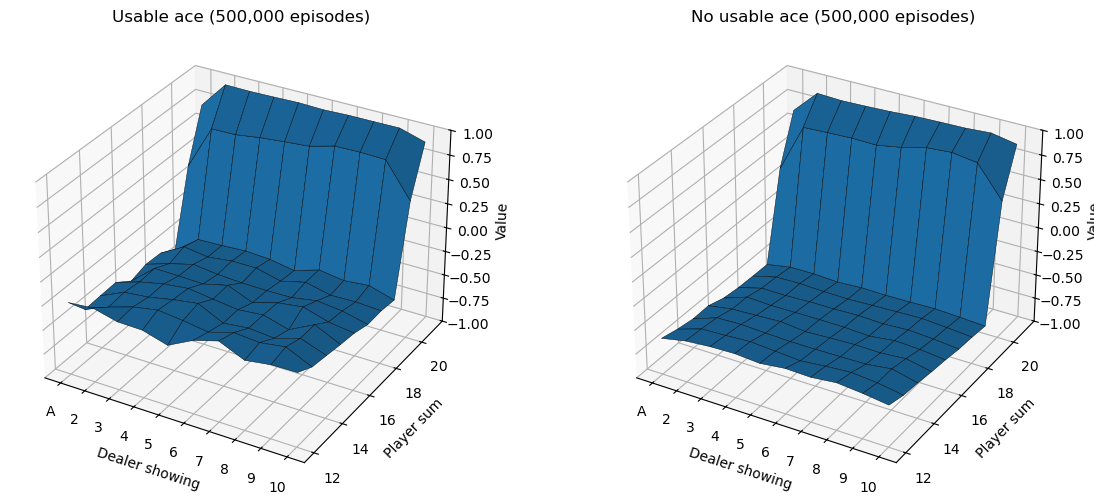

In [ ]:
""" CODE HERE YOUR IMPLEMENTATION for Q3-(a) """

STICK = 0
HIT = 1

# policy from the book: stick on 20 or 21, hit otherwise
def policy_20(state):
    player_sum = state[0]
    if player_sum >= 20:
        return STICK
    return HIT


# play one episode and return the states and rewards
def play_episode(env, policy):
    states = []
    rewards = []
    state, _ = env.reset()
    done = False
    while not done:
        # policy is policy 20
        action = policy(state)

        # next state: tuple (player_sum, dealer_card, usable_ace)
        # reward float 0.0 for the game still going and draw, and -1.0 for loss 1.0 for win
        # terminated and truncted are bools
        next_state, reward, terminated, truncated, _ = env.step(action)
        states.append(state)
        rewards.append(reward)
        state = next_state
        done = terminated or truncated
    return states, rewards


# first-visit MC prediction
def mc_prediction(env, policy, n_episodes, gamma=1.0):
    # V[player_sum, dealer_card, usable_ace: bool 0 or 1]
    V = np.zeros((32, 11, 2))
    counts = np.zeros((32, 11, 2))

    for ep in range(n_episodes):
        states, rewards = play_episode(env, policy)
        G = 0
        # go backwards through the episode
        for t in range(len(states) - 1, -1, -1):
            G = gamma * G + rewards[t]
            # only update on the first visit to this state
            if states[t] not in states[:t]:
                player, dealer, ace = states[t]

                # incremental average alogrithim from eailer
                idx = (player, dealer, int(ace))
                counts[idx] += 1
                V[idx] = V[idx] + (G - V[idx]) / counts[idx]
    return V


def plot_values(ax, values, title):
    x = np.arange(1, 11)    # dealer card (A-10)
    y = np.arange(12, 22)   # player sum (12-21)
    X, Y = np.meshgrid(x, y)

    # use the plot surface function for 3d plot
    ax.plot_surface(X, Y, values, edgecolor="k", linewidth=0.3)
    ax.set_xlabel("Dealer showing")
    ax.set_ylabel("Player sum")
    ax.set_zlabel("Value")
    ax.set_xticks(x)
    ax.set_xticklabels(["A", "2", "3", "4", "5", "6", "7", "8", "9", "10"])
    ax.set_zlim(-1, 1)
    ax.set_title(title)


# sab=True -> from the Sutton & Barto book
env = gym.make("Blackjack-v1", sab=True)
V = mc_prediction(env, policy_20, 500000)

fig = plt.figure(figsize=(14, 6))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
plot_values(ax1, V[12:22, 1:11, 1], "Usable ace (500,000 episodes)")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
plot_values(ax2, V[12:22, 1:11, 0], "No usable ace (500,000 episodes)")
plt.tight_layout()
plt.show()

## (b): Implement first-visit Monte-Carlo control with exploring starts (Monte-Carlo ES in 5.3). 

Please read Example 5.1 and reproduce Figure 5.2

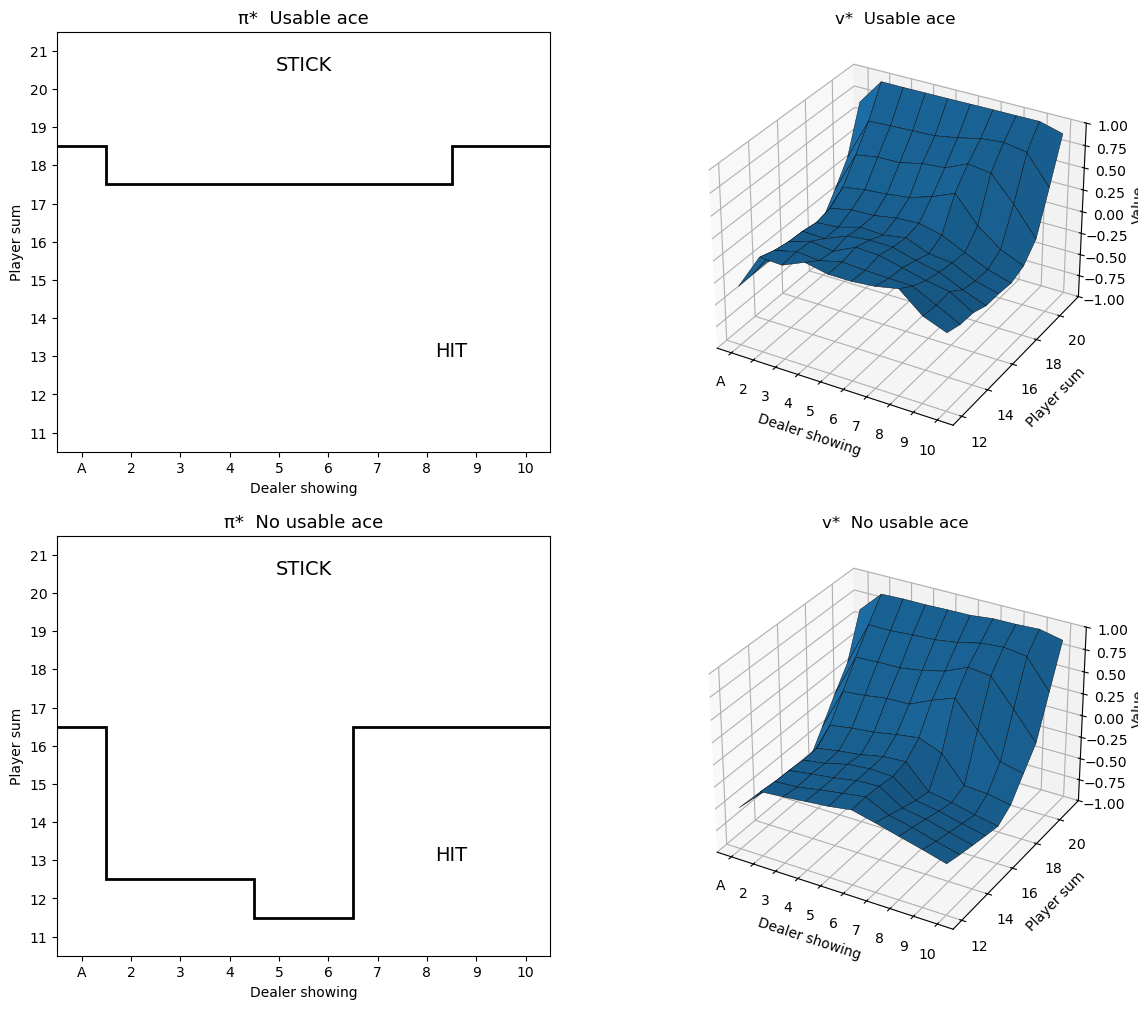

In [ ]:
""" CODE HERE YOUR IMPLEMENTATION for Q3-(b) """

# Monte Carlo ES (exploring starts)
def mc_es(env, n_episodes, gamma=1.0):
    # Q[player_sum, dealer_card, usable_ace: bool 0 or 1, action: 0 stick or 1 hit]
    Q = np.zeros((32, 11, 2, 2))
    counts = np.zeros((32, 11, 2, 2))

    # start with the policy from part (a): stick on 20 or 21, hit otherwise
    policy = np.ones((32, 11, 2), dtype=int)
    policy[20:22] = STICK

    for ep in range(n_episodes):
        # exploring start: reset gives a random starting state,
        # and we pick the first action at random so every action gets tried
        state, _ = env.reset()
        action = np.random.randint(2)

        episode = []   # list of (state, action, reward)
        done = False
        while not done:
            # next state: tuple (player_sum, dealer_card, usable_ace)
            # reward float 0.0 for the game still going and draw, and -1.0 for loss 1.0 for win
            # terminated and truncted are bools
            next_state, reward, terminated, truncated, _ = env.step(action)
            s = (state[0], state[1], int(state[2]))
            episode.append((s, action, reward))
            done = terminated or truncated
            if not done:
                state = next_state
                ns = (state[0], state[1], int(state[2]))
                action = policy[ns]   # after the first step, follow the greedy policy

        G = 0
        pairs = [(s, a) for s, a, r in episode]
        # go backwards through the episode
        for t in range(len(episode) - 1, -1, -1):
            s, a, r = episode[t]
            G = gamma * G + r
            # only update on the first visit to this (state, action) pair
            if (s, a) not in pairs[:t]:

                # incremental average alogrithim from eailer
                idx = s + (a,)
                counts[idx] += 1
                Q[idx] = Q[idx] + (G - Q[idx]) / counts[idx]

                # make the policy greedy for this state
                policy[s] = np.argmax(Q[s])
    return Q, policy


def plot_policy(ax, pol, title):
    # pol has shape (11, 10): rows = player sum 11-21, cols = dealer card A-10
    # for each dealer card, find the lowest player sum where we stick
    boundary = []
    for d in range(10):
        stick_sums = [11 + i for i in range(11) if pol[i, d] == STICK]
        if stick_sums:
            boundary.append(min(stick_sums) - 0.5)
        else:
            boundary.append(21.5)   # never sticks for this dealer card

    # draw the boundary as a step line: HIT below it, STICK above it
    ax.stairs(boundary, np.arange(0.5, 11.5), color="k", linewidth=2, baseline=None)

    ax.set_xlim(0.5, 10.5)
    ax.set_ylim(10.5, 21.5)
    ax.set_xticks(range(1, 11))
    ax.set_xticklabels(["A", "2", "3", "4", "5", "6", "7", "8", "9", "10"])
    ax.set_yticks(range(11, 22))
    ax.set_xlabel("Dealer showing")
    ax.set_ylabel("Player sum")
    ax.set_title(title, fontsize=13)
    ax.text(5.5, 20.5, "STICK", ha="center", fontsize=14)
    ax.text(8.5, 13.0, "HIT", ha="center", fontsize=14)


# sab=True -> from the Sutton & Barto book
env = gym.make("Blackjack-v1", sab=True)
Q, policy = mc_es(env, 3000000)   # takes ~2-3 min
V = Q.max(axis=3)                 # v*(s) = max over actions of Q(s, a)

fig = plt.figure(figsize=(14, 12))
ax1 = fig.add_subplot(2, 2, 1)
plot_policy(ax1, policy[11:22, 1:11, 1], "π*  Usable ace")
ax2 = fig.add_subplot(2, 2, 2, projection="3d")
plot_values(ax2, V[12:22, 1:11, 1], "v*  Usable ace")
ax3 = fig.add_subplot(2, 2, 3)
plot_policy(ax3, policy[11:22, 1:11, 0], "π*  No usable ace")
ax4 = fig.add_subplot(2, 2, 4, projection="3d")
plot_values(ax4, V[12:22, 1:11, 0], "v*  No usable ace")
plt.show()

# Q4: FrozenLake

We use the 4x4 slippery FrozenLake from Gymnasium. The agent starts in the top-left corner and must reach the goal in the bottom-right corner without falling into a hole. The reward is $+1$ for reaching the goal and $0$ otherwise. Each move goes in the intended direction with probability $1/3$ and in each of the two perpendicular directions with probability $1/3$. Episodes end at the goal, in a hole, or after 100 steps.

In [ ]:
# test code for using the "FrozenLake" implementation from Gymnasium
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True)
env.reset()

# interacting with the environment for 10 time steps using a random policy
for t in range(10):
    # sample a random action
    action = env.action_space.sample()

    # interact with the environment
    next_s, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated

    # print info
    print(f"t = {t}, next_state = {next_s}, reward = {reward}, done = {done}")

    # check termination
    if done:
        env.reset()

## (a): Implement on-policy first-visit Monte-Carlo control (for $\epsilon$-soft policies, see pseudocode in 5.4).

Use $\gamma = 0.99$, initialize $Q(s, a) = 0$, and break ties between greedy actions at random. Plot learning curves for $\epsilon = 0.1, 0.01, 0$ with the plotting function above.

epsilon = 0.1: average return over last 1000 episodes = 0.269
epsilon = 0.01: average return over last 1000 episodes = 0.265
epsilon = 0: average return over last 1000 episodes = 0.076


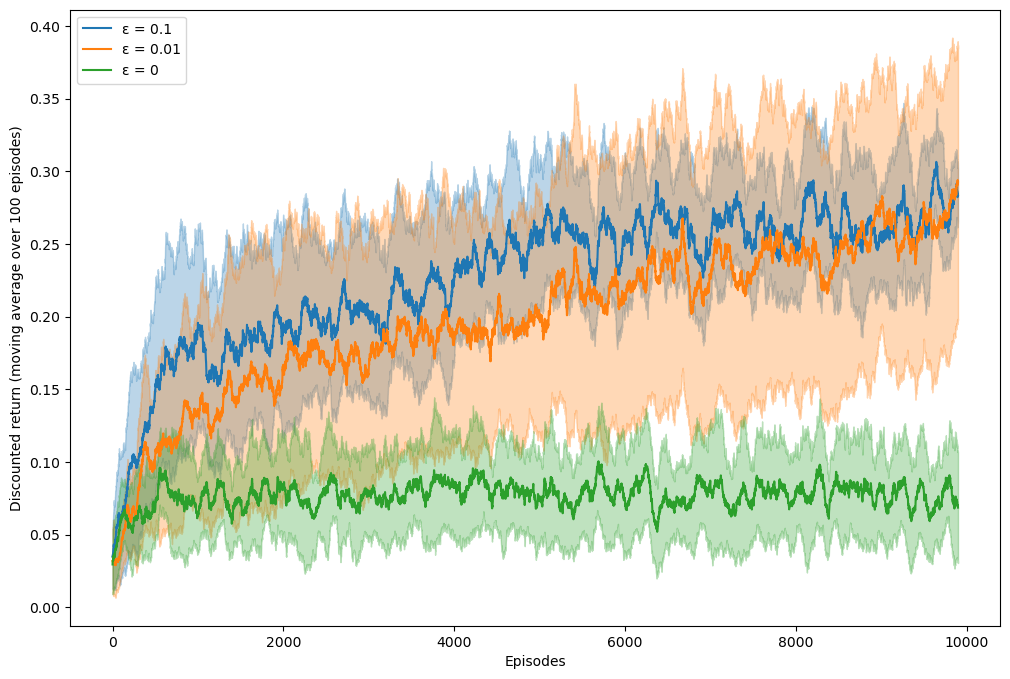

In [14]:
""" CODE HERE YOUR IMPLEMENTATION for Q4-(a) """

# pick an action with epsilon-greedy, breaking ties at random
def choose_action(Q, state, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(4))
    best = np.flatnonzero(Q[state] == Q[state].max())   # all greedy actions
    return int(rng.choice(best))


# on-policy first-visit MC control (epsilon-soft policy)
# returns the discounted return of every episode
def mc_control(env, n_episodes, epsilon, gamma=0.99, seed=0):
    rng = np.random.default_rng(seed)
    Q = np.zeros((16, 4))        # 16 cells, 4 actions (left, down, right, up)
    counts = np.zeros((16, 4))
    returns = np.zeros(n_episodes)

    state, _ = env.reset(seed=seed)
    for ep in range(n_episodes):
        # play one episode with the current epsilon-greedy policy
        episode = []   # list of (state, action, reward)
        state, _ = env.reset()
        done = False
        while not done:
            action = choose_action(Q, state, epsilon, rng)
            next_state, reward, terminated, truncated, _ = env.step(action)
            episode.append((state, action, reward))
            state = next_state
            done = terminated or truncated

        # go backwards through the episode
        G = 0
        pairs = [(s, a) for s, a, r in episode]
        for t in range(len(episode) - 1, -1, -1):
            # obtain our state, action, reward for the episode
            s, a, r = episode[t]
            # countinously update our goal
            G = gamma * G + r
            # only update on the first visit to this (state, action) pair
            if (s, a) not in pairs[:t]:
                counts[s, a] += 1
                # Q is the state and action - error / number of times that's it been seen
                Q[s, a] = Q[s, a] + (G - Q[s, a]) / counts[s, a]
        # (the policy is epsilon-greedy w.r.t. Q, so updating Q updates the policy)

        returns[ep] = G   # after the loop, G is the discounted return from the start
    return returns


env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True)
n_trials = 10
n_episodes = 10000    # use 5 trials and 10^4 episodes

results = []
for eps in [0.1, 0.01, 0]:
    runs = np.zeros((n_trials, n_episodes))
    for trial in range(n_trials):
        runs[trial] = mc_control(env, n_episodes, eps, seed=trial)
    results.append(runs)
    print(f"epsilon = {eps}: average return over last 1000 episodes = {runs[:, -1000:].mean():.3f}")


# I quickly realized that each episode's return is either 0 or close to 1, 
# so smooth each trial with a moving average over 100 episodes to see the trend
def smooth(runs, window=100):
    kernel = np.ones(window) / window
    return np.array([np.convolve(run, kernel, mode="valid") for run in runs])

plot_curves([smooth(r) for r in results], ["ε = 0.1", "ε = 0.01", "ε = 0"],
            ["tab:blue", "tab:orange", "tab:green"],
            ylabel="Discounted return (moving average over 100 episodes)")

# Q5: Racetrack

Please note, we provide you with the implementation of the two Racetrack domains in Figure 5.5. States are tuples `(x, y, v_x, v_y)` and actions are tuples `(Δv_x, Δv_y)` from `Racetrack.ACTIONS`, so both can be used directly as dictionary keys.

In [16]:
# Define the Racetrack domain 1
racetrack_v1_arr = np.array([
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3],
            [1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3],
            [1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3],
            [1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3],
            [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3],
            [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3],
            [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
            [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1]])

racetrack_v2_arr = np.array([
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1]])

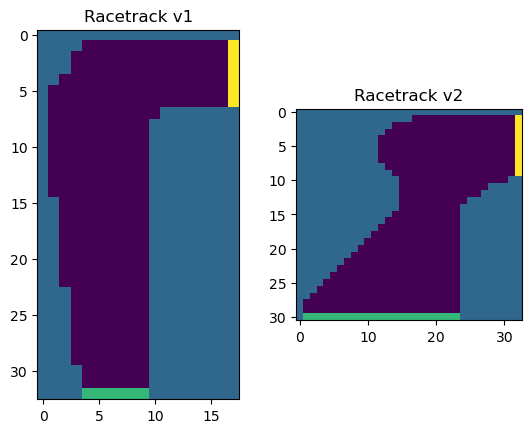

In [17]:
fig, arr = plt.subplots(1, 2)
arr[0].set_title("Racetrack v1")
arr[0].imshow(racetrack_v1_arr)
arr[1].set_title("Racetrack v2")
arr[1].imshow(racetrack_v2_arr)
plt.show()

In [18]:
type State = tuple[int, int, int, int]
"""(x, y, v_x, v_y), with x, y counted from the bottom-left cell"""
type Action = tuple[int, int]
"""(Δv_x, Δv_y), each in {-1, 0, 1}"""


class Racetrack:
    """Racetrack domain from RL2e Exercise 5.12. Do not change"""

    ACTIONS: tuple[Action, ...] = tuple((dx, dy) for dx in (-1, 0, 1) for dy in (-1, 0, 1))
    MAX_SPEED = 4

    def __init__(self, version: str, seed: int | None = None):
        """
        Args:
            version: "v1" or "v2", the left or right track in Figure 5.5
            seed: seed for the environment's random number generator
        """
        # cell values: 1 track boundary, 0 empty, 2 start line, 3 finish line
        self.domain_arr = {"v1": racetrack_v1_arr, "v2": racetrack_v2_arr}[version].copy()
        self.height, self.width = self.domain_arr.shape
        self.rng = np.random.default_rng(seed)

        self.empty_cell_locs = self.cell_locations(0)
        self.track_cell_locs = set(self.cell_locations(1))
        self.start_cell_locs = self.cell_locations(2)
        self.finish_cell_locs = set(self.cell_locations(3))

        self.action_space = list(self.ACTIONS)
        self.state_space: list[State] = [
            (x, y, vx, vy)
            for x, y in self.start_cell_locs + self.empty_cell_locs + sorted(self.finish_cell_locs)
            for vx in range(self.MAX_SPEED + 1)
            for vy in range(self.MAX_SPEED + 1)
        ]

        self.state: State | None = None
        self.action: Action | None = None
        self.t = 0

    def cell_locations(self, val: int) -> list[tuple[int, int]]:
        """(x, y) of every cell with this value, with y counted up from the bottom row"""
        rows, cols = np.nonzero(self.domain_arr == val)
        return [(int(c), self.height - 1 - int(r)) for r, c in zip(rows, cols)]

    def random_start(self) -> State:
        x, y = self.start_cell_locs[self.rng.integers(len(self.start_cell_locs))]
        return (x, y, 0, 0)

    def reset(self) -> tuple[State, None, bool]:
        """Start an episode on a random start-line cell with zero velocity

        Returns:
            (state, reward, done), where reward is None
        """
        self.state = self.random_start()
        self.action = None
        self.t = 0
        return self.state, None, False

    def step(self, state: State, action: Action) -> tuple[State, int, bool]:
        """
        Args:
            state: the agent's current state (x, y, v_x, v_y)
            action: the velocity increments (Δv_x, Δv_y)

        Returns:
            (next_state, reward, done). The reward is -1 for every step until the car crosses the finish line.
        """
        x, y, vx, vy = state
        self.t += 1

        # with probability 0.1, the velocity increments are both zero
        if self.rng.random() < 0.1:
            action = (0, 0)

        # both velocity components stay within [0, 4], and only the start line allows (0, 0)
        next_vx = min(max(vx + action[0], 0), self.MAX_SPEED)
        next_vy = min(max(vy + action[1], 0), self.MAX_SPEED)
        if (next_vx, next_vy) == (0, 0) and (x, y) not in self.start_cell_locs:
            if vx == 0:
                next_vy = 1
            elif vy == 0:
                next_vx = 1
            elif self.rng.random() < 0.5:
                next_vx = 1
            else:
                next_vy = 1

        # follow the projected path one cell at a time, so the car cannot jump over the boundary
        n = max(next_vx, next_vy)
        for k in range(1, n + 1):
            cell = (x + round(k * next_vx / n), y + round(k * next_vy / n))
            if cell in self.finish_cell_locs:
                self.state, self.action = (*cell, next_vx, next_vy), action
                return self.state, 0, True
            outside = not (0 <= cell[0] < self.width and 0 <= cell[1] < self.height)
            if outside or cell in self.track_cell_locs:
                # back to a random start-line cell with zero velocity, and the episode continues
                self.state, self.action = self.random_start(), action
                return self.state, -1, False

        self.state, self.action = (x + next_vx, y + next_vy, next_vx, next_vy), action
        return self.state, -1, False

    def render(self):
        plt.clf()
        plt.title(f"s = {self.state}, a = {self.action}")
        plot_arr = self.domain_arr.copy()
        plot_arr[(self.height - 1) - self.state[1], self.state[0]] = 4
        plt.imshow(plot_arr)
        plt.show(block=False)
        plt.pause(0.01)

## (a): Implement first-visit Monte-Carlo control with an epsilon-greedy policy (epsilon = 0.1)

- Plot the learning curves for the two tracks.
- Use running trials number = 10 and episodes number = 2000

track v1: average return over last 100 episodes = -205.3


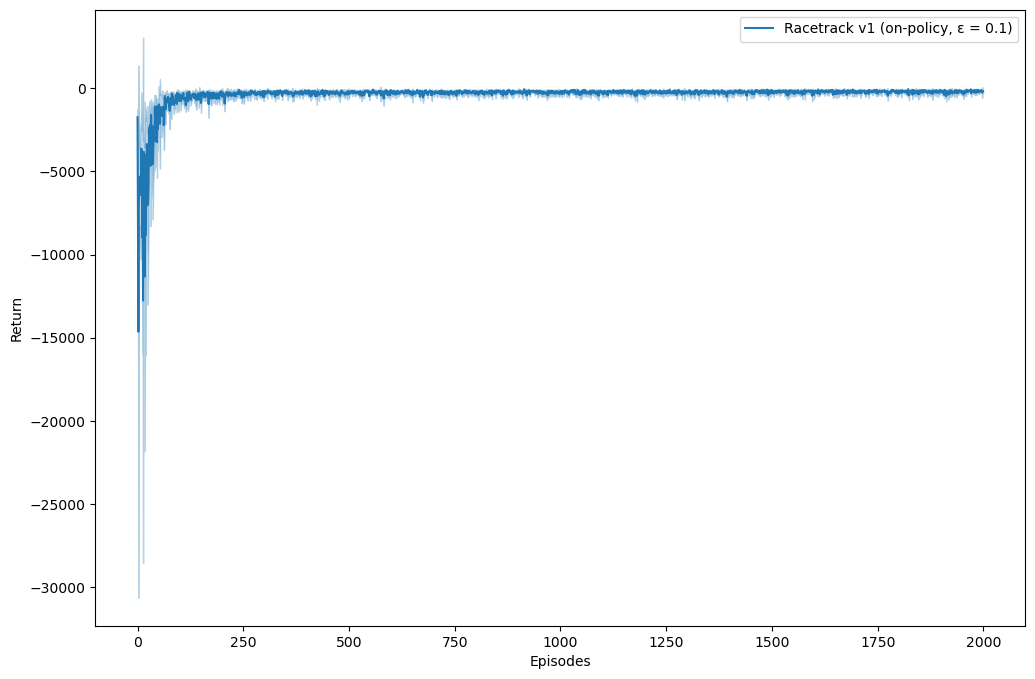

track v2: average return over last 100 episodes = -35.6


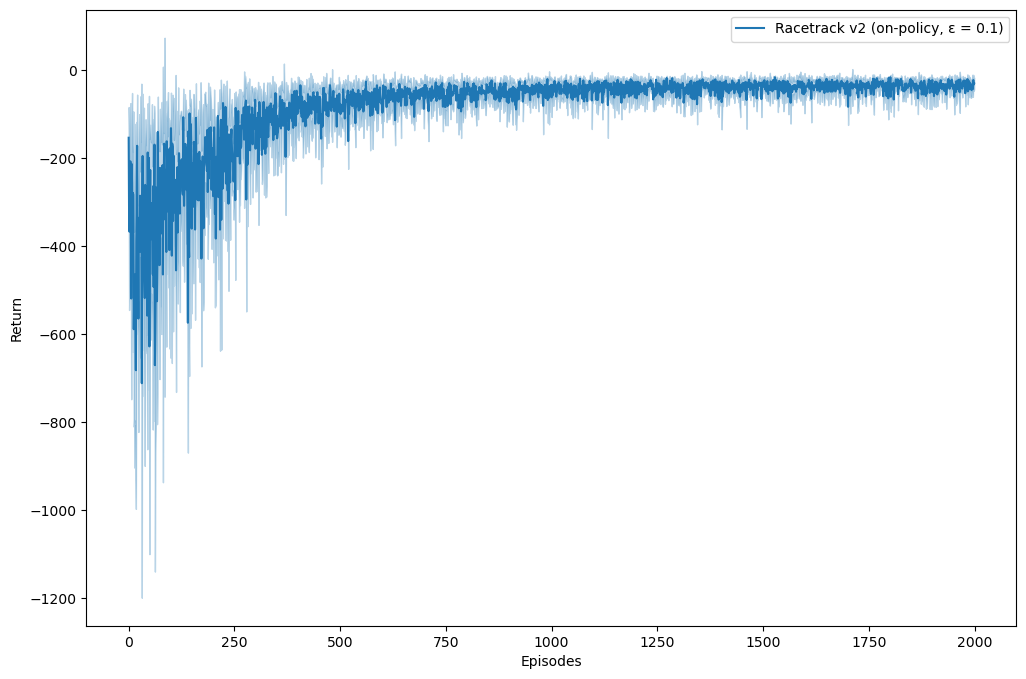

In [ ]:
""" CODE HERE YOUR IMPLEMENTATION for Q5-(a) """

ACTIONS = Racetrack.ACTIONS   # 9 actions: (dvx, dvy) with each in {-1, 0, 1}

# pick an action index with epsilon-greedy, breaking ties at random
# (same idea as choose_action in Q4, but Q is a dict since states are tuples)
def choose_action_rt(Q, state, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(9))
    q = Q[state]
    best = np.flatnonzero(q == q.max())   # all greedy actions
    return int(rng.choice(best))


# on-policy first-visit MC control (epsilon-soft policy) for the racetrack
# returns the return of every episode
def mc_control_rt(env, n_episodes, epsilon=0.1, gamma=1.0, seed=0):
    rng = np.random.default_rng(seed)
    # Q[state] = array of 9 action values, state = (x, y, vx, vy)
    Q = {s: np.zeros(9) for s in env.state_space}
    counts = {s: np.zeros(9) for s in env.state_space}
    returns = np.zeros(n_episodes)

    for ep in range(n_episodes):
        # play one episode with the current epsilon-greedy policy
        episode = []   # list of (state, action index, reward)
        state, _, done = env.reset()
        while not done:
            a = choose_action_rt(Q, state, epsilon, rng)

            # next state: tuple (x, y, vx, vy)
            # reward int -1 for every step, 0 when crossing the finish line
            # done is a bool, True when the car crosses the finish line
            next_state, reward, done = env.step(state, ACTIONS[a])
            episode.append((state, a, reward))
            state = next_state

        # first time each (state, action) pair shows up in the episode
        # (episodes can be long here, so this is faster than checking pairs[:t])
        first_visit = {}
        for t, (s, a, r) in enumerate(episode):
            if (s, a) not in first_visit:
                first_visit[(s, a)] = t

        G = 0
        # go backwards through the episode as we've done everytime
        for t in range(len(episode) - 1, -1, -1):
            s, a, r = episode[t]
            G = gamma * G + r
            # only update on the first visit to this (state, action) pair
            if first_visit[(s, a)] == t:

                # incremental average alogrithim from eailer
                counts[s][a] += 1
                Q[s][a] = Q[s][a] + (G - Q[s][a]) / counts[s][a]

        returns[ep] = G   # return from the start = -(number of steps)
    return returns


n_trials = 10
n_episodes = 2000

for track in ["v1", "v2"]:
    runs = np.zeros((n_trials, n_episodes))
    for trial in range(n_trials):
        env = Racetrack(track, seed=trial)
        runs[trial] = mc_control_rt(env, n_episodes, epsilon=0.1, seed=trial)
    print(f"track {track}: average return over last 100 episodes = {runs[:, -100:].mean():.1f}")
    plot_curves([runs], [f"Racetrack {track} (on-policy, ε = 0.1)"], ["tab:blue"], ylabel="Return")

## (b): Implement off-policy Monte-Carlo control. Please specify what behavior policy you are using.

- Use only the right-hand track, `Racetrack("v2")`, and plot its learning curve
- Using running trials number = 10 and episodes number = 2000
- Early in training the greedy target policy may never reach the finish line, so cap the evaluation rollouts (e.g. at 1000 steps)

average target-policy return over last 100 episodes = -254.3


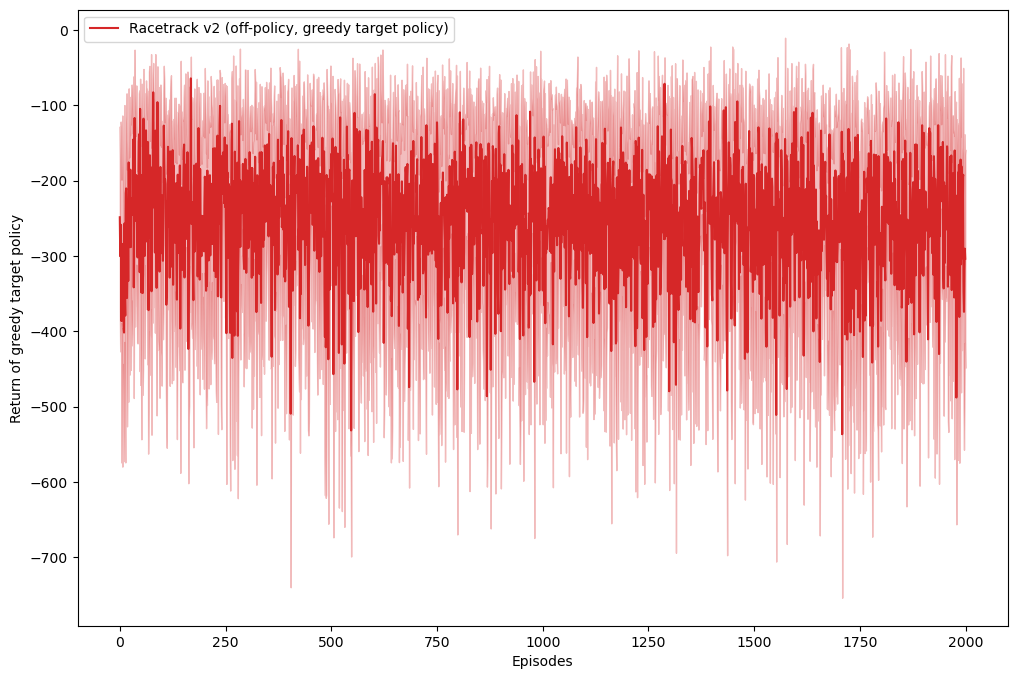

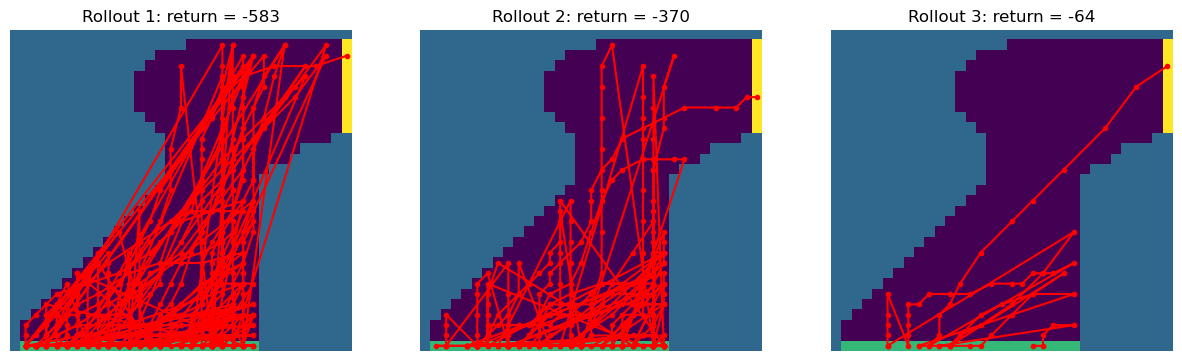

In [ ]:
""" CODE HERE YOUR IMPLEMENTATION for Q5-(b) """

# Behavior policy b: epsilon-greedy (epsilon = 0.1) w.r.t. the latest Q, ties broken at random
# Target policy pi: greedy w.r.t. Q

# greedy action of the target policy (ties broken at random)
def greedy_action(Q, state, rng):
    return choose_action_rt(Q, state, 0.0, rng)


# probability that the epsilon-greedy behavior policy picks action a in this state
def behavior_probability(Q, state, a, epsilon):
    q = Q[state]
    best = np.flatnonzero(q == q.max())   # all greedy actions
    prob = epsilon / 9
    if a in best:
        prob += (1 - epsilon) / len(best)
    return prob


# play one rollout with the greedy target policy (only for evaluation, no learning)
# capped at max_steps because early on the greedy policy may never finish
def greedy_rollout(env, Q, rng, max_steps=1000):
    state, _, done = env.reset()
    G = 0
    path = [state]
    for step in range(max_steps):
        a = greedy_action(Q, state, rng)
        state, reward, done = env.step(state, ACTIONS[a])
        # accumulate the reward
        G += reward
        path.append(state)
        if done:
            break
    return G, path


# off-policy MC control with weighted importance sampling (RL2e Sec. 5.7)
# returns the return of the greedy target policy after every episode
def off_policy_mc(env, n_episodes, epsilon=0.1, gamma=1.0, seed=0, q_init=0.0):
    rng = np.random.default_rng(seed)
    # Q[state] = array of 9 action values, state = (x, y, vx, vy)
    Q = {s: np.full(9, q_init) for s in env.state_space}
    C = {s: np.zeros(9) for s in env.state_space}   # sum of importance weights
    eval_returns = np.zeros(n_episodes)
    eval_env = Racetrack("v2", seed=seed + 1000)   # separate copy of the track just for evaluation

    for ep in range(n_episodes):
        # play one episode with the behavior policy b (epsilon-greedy)
        episode = []   # list of (state, action index, reward, b(a|s))
        state, _, done = env.reset()
        while not done:
            a = choose_action_rt(Q, state, epsilon, rng)
            b_prob = behavior_probability(Q, state, a, epsilon)

            # next state: tuple (x, y, vx, vy)
            # reward int -1 for every step, 0 when crossing the finish line
            # done is a bool, True when the car crosses the finish line
            next_state, reward, done = env.step(state, ACTIONS[a])
            episode.append((state, a, reward, b_prob))
            state = next_state

        G = 0
        W = 1.0   # importance sampling ratio
        # go backwards through the episode
        for t in range(len(episode) - 1, -1, -1):
            s, a, r, b_prob = episode[t]
            G = gamma * G + r
            C[s][a] += W
            # weighted average: move Q toward G by W / C instead of 1 / count
            Q[s][a] = Q[s][a] + (W / C[s][a]) * (G - Q[s][a])
            # target policy is greedy, so if b took a different action,
            # pi(a|s) = 0 and the earlier steps get weight 0 -> stop
            if a != greedy_action(Q, s, rng):
                break
            # pi(a|s) = 1, so W gets multiplied by 1 / b(a|s)
            W = W / b_prob

        # evaluate the greedy target policy with one rollout
        eval_returns[ep], _ = greedy_rollout(eval_env, Q, rng)
    return eval_returns, Q


n_trials = 10
n_episodes = 2000

runs = np.zeros((n_trials, n_episodes))
for trial in range(n_trials):
    env = Racetrack("v2", seed=trial)
    runs[trial], Q = off_policy_mc(env, n_episodes, epsilon=0.1, seed=trial)
print(f"average target-policy return over last 100 episodes = {runs[:, -100:].mean():.1f}")
plot_curves([runs], ["Racetrack v2 (off-policy, greedy target policy)"], ["tab:red"],
            ylabel="Return of greedy target policy")


# visualize a few rollouts of the learned target policy (Q from the last trial)
rng = np.random.default_rng(0)
eval_env = Racetrack("v2", seed=123)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, ax in enumerate(axes):
    G, path = greedy_rollout(eval_env, Q, rng)
    ax.imshow(eval_env.domain_arr)
    xs = [s[0] for s in path]
    rows = [eval_env.height - 1 - s[1] for s in path]   # y counts from the bottom, imshow rows from the top
    ax.plot(xs, rows, "r.-")
    ax.set_title(f"Rollout {i + 1}: return = {G}")
    ax.axis("off")
plt.show()